In [1]:
import os
import numpy as np
import rasterio
from scipy.stats import pearsonr

# ======================
# FOLDERS
# ======================
vci_folder = r"C:\Users\gerii\Documents\projects\tekeze\VCI"
tci_folder = r"C:\Users\gerii\Documents\projects\tekeze\TCI"
out_folder = r"C:\Users\gerii\Documents\projects\tekeze\VHI"

os.makedirs(out_folder, exist_ok=True)

# ======================
# LOAD FILES
# ======================
vci_files = sorted([f for f in os.listdir(vci_folder) if f.endswith(".tif")])
tci_files = sorted([f for f in os.listdir(tci_folder) if f.endswith(".tif")])

print("VCI:", len(vci_files), "TCI:", len(tci_files))

# ======================
# READ STACKS
# ======================
def load_stack(folder, files):
    stack = []
    meta = None

    for f in files:
        with rasterio.open(os.path.join(folder, f)) as src:
            data = src.read(1).astype("float32")
            data[(data < 0) | (data > 1)] = np.nan

            stack.append(data)

            if meta is None:
                meta = src.meta.copy()

    return np.array(stack), meta

vci_stack, meta = load_stack(vci_folder, vci_files)
tci_stack, _ = load_stack(tci_folder, tci_files)

print("Stacks loaded:", vci_stack.shape)

# ======================
# FLATTEN FOR ANALYSIS
# ======================
vci_flat = vci_stack.reshape(vci_stack.shape[0], -1)
tci_flat = tci_stack.reshape(tci_stack.shape[0], -1)

# remove NaNs consistently
mask = ~np.isnan(vci_flat).any(axis=0) & ~np.isnan(tci_flat).any(axis=0)

vci_flat = vci_flat[:, mask]
tci_flat = tci_flat[:, mask]

# ======================
# FIND BEST ALPHA
# ======================
alphas = np.arange(0.1, 1.0, 0.1)
best_alpha = None
best_score = -1

for a in alphas:

    vhi = a * vci_flat + (1 - a) * tci_flat

    # stability metric: correlation between VHI and components
    score_vci = np.mean([pearsonr(vhi[i], vci_flat[i])[0] for i in range(len(vci_flat))])
    score_tci = np.mean([pearsonr(vhi[i], tci_flat[i])[0] for i in range(len(tci_flat))])

    score = (score_vci + score_tci) / 2

    print(f"alpha={a:.1f}, score={score:.3f}")

    if score > best_score:
        best_score = score
        best_alpha = a

print("\nBEST ALPHA:", best_alpha)

# ======================
# BUILD FINAL VHI STACK
# ======================
final_vhi_stack = best_alpha * vci_stack + (1 - best_alpha) * tci_stack
final_vhi_stack = np.clip(final_vhi_stack, 0, 1)

meta.update(dtype="float32", count=1)

# ======================
# SAVE VHI
# ======================
for i, f in enumerate(vci_files):

    out_name = f.replace("VCI_", "VHI_")
    out_path = os.path.join(out_folder, out_name)

    with rasterio.open(out_path, "w", **meta) as dst:
        dst.write(final_vhi_stack[i].astype("float32"), 1)

    print("Saved:", out_name)

print("\nVHI generation complete ✔")

VCI: 311 TCI: 311
Stacks loaded: (311, 337, 407)
alpha=0.1, score=0.792
alpha=0.2, score=0.823
alpha=0.3, score=0.844
alpha=0.4, score=0.856
alpha=0.5, score=0.858
alpha=0.6, score=0.851
alpha=0.7, score=0.835
alpha=0.8, score=0.812
alpha=0.9, score=0.784

BEST ALPHA: 0.5
Saved: VHI_2000_02.tif
Saved: VHI_2000_03.tif
Saved: VHI_2000_04.tif
Saved: VHI_2000_05.tif
Saved: VHI_2000_06.tif
Saved: VHI_2000_07.tif
Saved: VHI_2000_08.tif
Saved: VHI_2000_09.tif
Saved: VHI_2000_10.tif
Saved: VHI_2000_11.tif
Saved: VHI_2000_12.tif
Saved: VHI_2001_01.tif
Saved: VHI_2001_02.tif
Saved: VHI_2001_03.tif
Saved: VHI_2001_04.tif
Saved: VHI_2001_05.tif
Saved: VHI_2001_06.tif
Saved: VHI_2001_07.tif
Saved: VHI_2001_08.tif
Saved: VHI_2001_09.tif
Saved: VHI_2001_10.tif
Saved: VHI_2001_11.tif
Saved: VHI_2001_12.tif
Saved: VHI_2002_01.tif
Saved: VHI_2002_02.tif
Saved: VHI_2002_03.tif
Saved: VHI_2002_04.tif
Saved: VHI_2002_05.tif
Saved: VHI_2002_06.tif
Saved: VHI_2002_07.tif
Saved: VHI_2002_08.tif
Saved: VHI_200

### VHI visualize 2010

Files found: 12


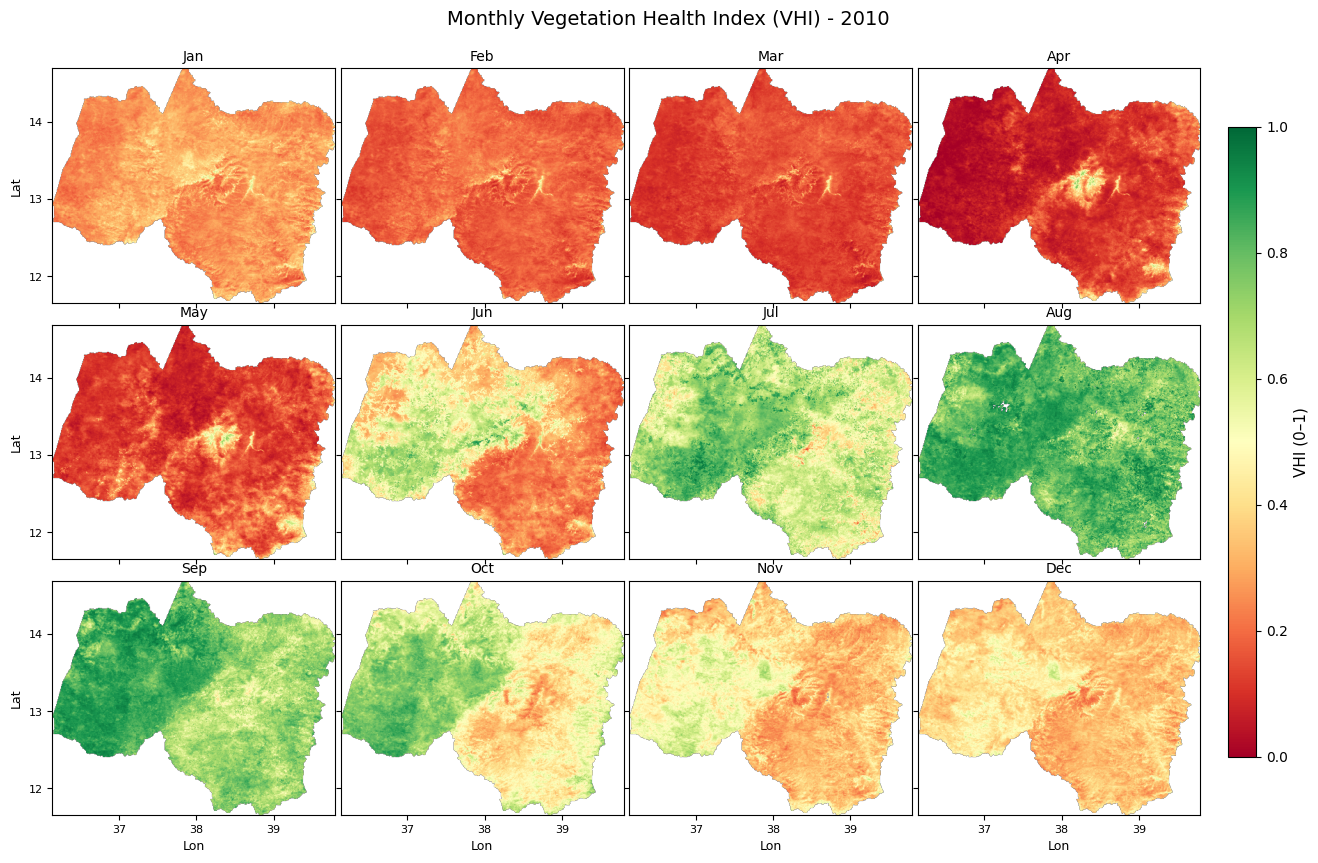

In [2]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ======================
# Folder (VHI outputs)
# ======================
folder = r"C:\Users\gerii\Documents\projects\tekeze\VHI"

files = sorted([
    f for f in os.listdir(folder)
    if f.startswith("VHI_2010") and f.endswith(".tif")
])

print("Files found:", len(files))

# ======================
# Figure
# ======================
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
axes = axes.flatten()

months = ["Jan","Feb","Mar","Apr","May","Jun",
          "Jul","Aug","Sep","Oct","Nov","Dec"]

# ======================
# VHI range (0–1)
# ======================
vmin = 0
vmax = 1

# ======================
# Plot
# ======================
for i, f in enumerate(files):

    path = os.path.join(folder, f)

    with rasterio.open(path) as src:
        data = src.read(1).astype("float32")

        # mask invalid
        data[(data < 0) | (data > 1)] = np.nan

        bounds = src.bounds
        extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

    ax = axes[i]

    im = ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap="RdYlGn",   # green = healthy, red = drought
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(months[i], fontsize=10)

    # ======================
    # 1-degree ticks
    # ======================
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.tick_params(labelsize=8)

    # ======================
    # Axis styling
    # ======================
    row = i // 4
    col = i % 4

    if col == 0:
        ax.set_ylabel("Lat", fontsize=9)
    else:
        ax.set_yticklabels([])

    if row == 2:
        ax.set_xlabel("Lon", fontsize=9)
    else:
        ax.set_xticklabels([])

# ======================
# Remove empty axes
# ======================
for j in range(len(files), 12):
    axes[j].axis("off")

# ======================
# Layout
# ======================
plt.subplots_adjust(
    left=0.06,
    right=0.88,
    top=0.92,
    bottom=0.08,
    wspace=0.02,
    hspace=0.05
)

# ======================
# Colorbar
# ======================
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("VHI (0–1)", fontsize=11)

# ======================
# Title
# ======================
plt.suptitle("Monthly Vegetation Health Index (VHI) - 2010", fontsize=14)

# ======================
# Save
# ======================
fig.canvas.draw()
fig.savefig(
    r"C:\Users\gerii\Documents\projects\tekeze\VHI\VHI_2010_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

### VHI annual drought affected area(km2) and %

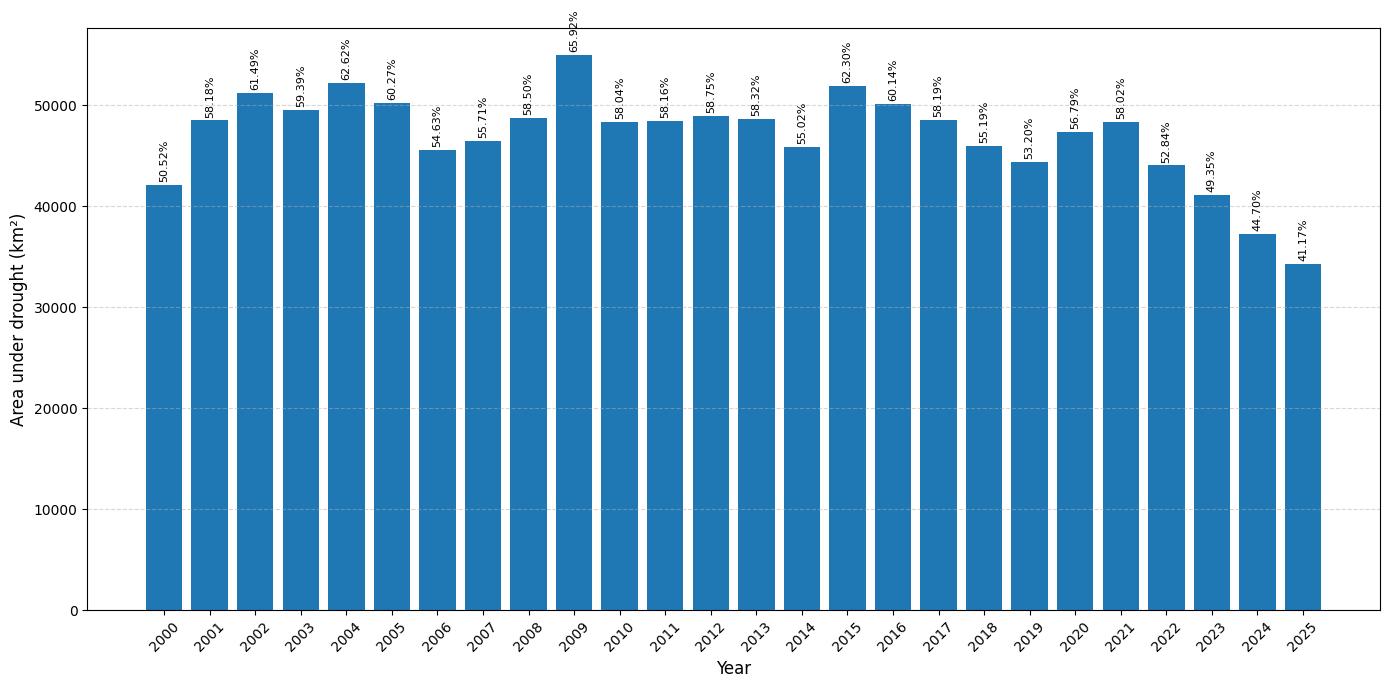

In [6]:
import matplotlib.pyplot as plt

# Data
years = [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009,
         2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019,
         2020, 2021, 2022, 2023, 2024, 2025]

area_km2 = [42111.17, 48498.06, 51258.26, 49509.86, 52204.23, 50238.05,
            45537.40, 46438.52, 48766.26, 54949.18, 48383.50, 48481.39,
            48977.05, 48619.93, 45864.58, 51931.75, 50129.44, 48509.81,
            46007.33, 44350.07, 47342.73, 48366.27, 44046.63, 41142.34,
            37265.87, 34319.66]

percentages = [50.52, 58.18, 61.49, 59.39, 62.62, 60.27, 54.63, 55.71,
               58.50, 65.92, 58.04, 58.16, 58.75, 58.32, 55.02, 62.30,
               60.14, 58.19, 55.19, 53.20, 56.79, 58.02, 52.84, 49.35,
               44.70, 41.17]

# Create figure
plt.figure(figsize=(14, 7))

# Bar chart
bars = plt.bar(years, area_km2)

# Add percentage labels above bars
for bar, pct in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 300,
        f'{pct:.2f}%',
        ha='center',
        va='bottom',
        fontsize=8,
        rotation=90
    )

# Axis labels and title
plt.xlabel('Year', fontsize=12)
plt.ylabel('Area under drought (km²)', fontsize=12)
#plt.title('Annual Area under Drought and Percentage Coverage (2000–2025)', fontsize=14)

# Format x-axis
plt.xticks(years, rotation=45)

# Add grid
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

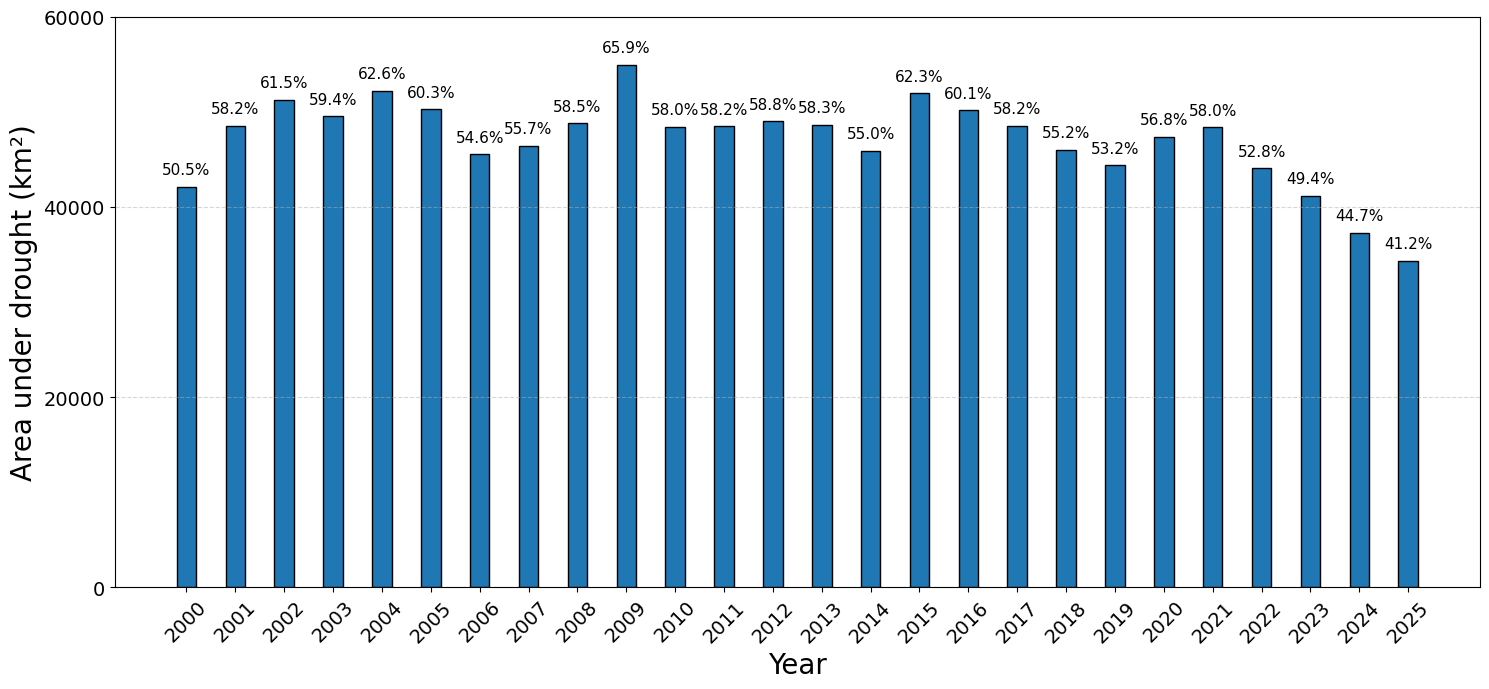

In [20]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# Data
years = [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009,
         2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019,
         2020, 2021, 2022, 2023, 2024, 2025]

area_km2 = [42111.17, 48498.06, 51258.26, 49509.86, 52204.23, 50238.05,
            45537.40, 46438.52, 48766.26, 54949.18, 48383.50, 48481.39,
            48977.05, 48619.93, 45864.58, 51931.75, 50129.44, 48509.81,
            46007.33, 44350.07, 47342.73, 48366.27, 44046.63, 41142.34,
            37265.87, 34319.66]

percentages = [50.5, 58.2, 61.5, 59.4, 62.6, 60.3, 54.6, 55.7,
               58.5, 65.9, 58.0, 58.2, 58.8, 58.3, 55.0, 62.3,
               60.1, 58.2, 55.2, 53.2, 56.8, 58.0, 52.8, 49.4,
               44.7, 41.2]

# Create figure
fig, ax = plt.subplots(figsize=(15, 7))

# Bar chart with increased spacing between bars
bars = ax.bar(years, area_km2, width=0.4, edgecolor='black')

# Percentage labels (horizontal)
for bar, pct in zip(bars, percentages):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1000,
        f'{pct:.1f}%',
        ha='center',
        va='bottom',
        fontsize=11,
        rotation=0
    )

# Axis labels
ax.set_xlabel('Year', fontsize=20)
ax.set_ylabel('Area under drought (km²)', fontsize=20)

# X-axis formatting
ax.set_xticks(years)
ax.set_xticklabels(years, rotation=45, fontsize=14)

# Y-axis formatting
ax.yaxis.set_major_locator(MultipleLocator(20000))
ax.set_ylim(0, 60000)

# Tick label size
ax.tick_params(axis='y', labelsize=14)

# Grid
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

# Save high-resolution figure
plt.savefig('drought_area_bar_chart.png', dpi=600, bbox_inches='tight')

plt.show()